# Cross-Domain Review Sentiment Classification

This notebook implements Option 2 (Review Sentiment Analysis) for ARTI 404. It trains a binary sentiment classifier (Positive/Negative) on Amazon product and IMDb movie reviews, then evaluates it on an in-domain held-out test and on a cross-domain Yelp restaurant test.

Experimental question: which method performs better on restaurant reviews when trained on product and movie reviews? The main judgment is Macro F1 on the Yelp test, with Accuracy reported alongside; the in-domain test is a supporting comparison only. Two methods are compared: TF-IDF + Logistic Regression (Method 1) and frozen MiniLM sentence embeddings + Logistic Regression (Method 2). Settings for both methods are selected on Development data only; neither test set is used for tuning.

## Setup

Import the libraries used across the notebook.

In [1]:
import platform
import random
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sentence_transformers
import sklearn
import torch

C:\Users\moham\Desktop\nlp project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fix the random seed so splits, shuffling and model fitting are reproducible.

In [2]:
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

Define relative project paths and create the output folders if they do not already exist. The notebook is expected to run from the project root, so every path here is relative rather than a path tied to one member's machine.

In [3]:
PROJECT_ROOT = Path.cwd()
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
RESULTS = PROJECT_ROOT / "results"
MODELS = PROJECT_ROOT / "models"

for path in (DATA_RAW, DATA_PROCESSED, RESULTS, MODELS):
    path.mkdir(parents=True, exist_ok=True)

Record the exact package versions used in this run, so the environment can be reproduced later.

In [4]:
print("Python:", platform.python_version())
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("sentence-transformers:", sentence_transformers.__version__)
print("torch:", torch.__version__)

Python: 3.12.10
numpy: 2.5.4
pandas: 3.1.1
scikit-learn: 1.9.1
sentence-transformers: 6.2.0
torch: 2.15.0+cpu


## Data

Download the UCI Sentiment Labelled Sentences archive into `data/raw/` if it is not already there, and extract it. The download is skipped when the three required files are already present; `__MACOSX` entries added by macOS zip tools are ignored everywhere below.

In [5]:
import datetime
import json
import urllib.request
import zipfile

DATA_URL = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
RAW_ZIP_PATH = DATA_RAW / "sentiment+labelled+sentences.zip"
DOWNLOAD_INFO_PATH = DATA_RAW / "download_info.json"
REQUIRED_FILES = ["amazon_cells_labelled.txt", "imdb_labelled.txt", "yelp_labelled.txt"]


def find_file(filename):
    matches = [p for p in DATA_RAW.rglob(filename) if "__MACOSX" not in p.parts]
    return matches[0] if matches else None


existing_files = {name: find_file(name) for name in REQUIRED_FILES}

if all(existing_files.values()):
    print("Required data files already present in data/raw/, skipping download.")
    if DOWNLOAD_INFO_PATH.exists():
        recorded = json.loads(DOWNLOAD_INFO_PATH.read_text())
        print("Recorded download date:", recorded["download_date"])
    else:
        print("Recorded download date: unknown (no download_info.json found).")
else:
    download_date = datetime.date.today().isoformat()
    urllib.request.urlretrieve(DATA_URL, RAW_ZIP_PATH)
    with zipfile.ZipFile(RAW_ZIP_PATH) as archive:
        archive.extractall(DATA_RAW)
    DOWNLOAD_INFO_PATH.write_text(
        json.dumps({"source": DATA_URL, "download_date": download_date}, indent=2)
    )
    existing_files = {name: find_file(name) for name in REQUIRED_FILES}
    print(f"Downloaded and extracted on {download_date}.")

print("\nFiles found in data/raw/ (excluding __MACOSX):")
for path in sorted(DATA_RAW.rglob("*")):
    if path.is_file() and "__MACOSX" not in path.parts:
        print(" -", path.relative_to(PROJECT_ROOT))

missing = [name for name, path in existing_files.items() if path is None]
if missing:
    raise FileNotFoundError(f"Required file(s) not found after download: {missing}")

Required data files already present in data/raw/, skipping download.
Recorded download date: 2026-11-11

Files found in data/raw/ (excluding __MACOSX):
 - data\raw\download_info.json
 - data\raw\sentiment labelled sentences\.DS_Store
 - data\raw\sentiment labelled sentences\amazon_cells_labelled.txt
 - data\raw\sentiment labelled sentences\imdb_labelled.txt
 - data\raw\sentiment labelled sentences\readme.txt
 - data\raw\sentiment labelled sentences\yelp_labelled.txt
 - data\raw\sentiment+labelled+sentences.zip


Read each source file line by line and split on the last tab, since the label is always the final field and the review text itself may contain other whitespace. Lines that fail to parse are reported, not dropped silently. Cleaning is limited to Unicode normalisation and whitespace collapsing so negation words are preserved and the stored text is not lowercased.

In [6]:
import unicodedata


def clean_text(text: str) -> str:
    # NFKC normalises compatibility characters (e.g. full-width punctuation);
    # whitespace is then collapsed without touching negation words.
    normalized = unicodedata.normalize("NFKC", text)
    return " ".join(normalized.split())


def load_data(path: Path, source: str) -> tuple[pd.DataFrame, list[str]]:
    rows = []
    invalid_lines = []
    with path.open("r", encoding="utf-8") as handle:
        for line_number, raw_line in enumerate(handle, start=1):
            line = raw_line.rstrip("\n").rstrip("\r")
            if not line.strip():
                invalid_lines.append(f"{source} line {line_number}: empty line")
                continue
            if "\t" not in line:
                invalid_lines.append(f"{source} line {line_number}: no tab separator")
                continue
            text_part, _, label_part = line.rpartition("\t")
            text = clean_text(text_part)
            label_part = label_part.strip()
            if label_part not in ("0", "1"):
                invalid_lines.append(
                    f"{source} line {line_number}: invalid label {label_part!r}"
                )
                continue
            if not text:
                invalid_lines.append(f"{source} line {line_number}: empty text")
                continue
            rows.append(
                {
                    "example_id": f"{source}_{line_number:04d}",
                    "source": source,
                    "text": text,
                    "label": int(label_part),
                }
            )
    return pd.DataFrame(rows), invalid_lines

Load all three sources and collect any invalid lines found during parsing.

In [7]:
FILENAME_BY_SOURCE = {
    "amazon": "amazon_cells_labelled.txt",
    "imdb": "imdb_labelled.txt",
    "yelp": "yelp_labelled.txt",
}

frames = []
all_invalid_lines = []
for source, filename in FILENAME_BY_SOURCE.items():
    frame, invalid_lines = load_data(existing_files[filename], source)
    frames.append(frame)
    all_invalid_lines.extend(invalid_lines)

raw_df = pd.concat(frames, ignore_index=True)

print(f"Loaded {len(raw_df)} valid rows from {len(FILENAME_BY_SOURCE)} source files.")
print(f"Invalid lines found: {len(all_invalid_lines)}")
for entry in all_invalid_lines:
    print(" -", entry)

Loaded 3000 valid rows from 3 source files.
Invalid lines found: 0


Counts by source and label, before any duplicate handling.

In [8]:
count_table = (
    raw_df.groupby(["source", "label"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "negative_0", 1: "positive_1"})
)
count_table["total"] = count_table["negative_0"] + count_table["positive_1"]
count_table

label,negative_0,positive_1,total
source,,,
amazon,500,500,1000
imdb,500,500,1000
yelp,500,500,1000


Build a `duplicate_key` for auditing only (lowercased, whitespace-collapsed text; punctuation and negation words are kept). The stored `text` column is never changed by this key.

In [9]:
def make_duplicate_key(text: str) -> str:
    return " ".join(text.lower().split())


raw_df["duplicate_key"] = raw_df["text"].apply(make_duplicate_key)

Audit duplicate_key groups across all three sources. A group with conflicting labels is dropped entirely and logged as a conflict. A group sharing one label keeps exactly one row, chosen by a fixed source priority (Yelp, then Amazon, then IMDb, then order of appearance in the source file) so a sentence that occurs in Yelp stays in the cross-domain test source rather than in training. No model output is used in this decision.

In [10]:
SOURCE_PRIORITY = {"yelp": 0, "amazon": 1, "imdb": 2}


def audit_duplicates(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    kept_rows = []
    removed_records = []
    within_source_keys = []
    across_source_keys = []
    conflict_keys = []

    for key, group in df.groupby("duplicate_key", sort=False):
        if len(group) == 1:
            kept_rows.append(group.iloc[0])
            continue

        is_cross_source = group["source"].nunique() > 1

        if group["label"].nunique() > 1:
            conflict_keys.append(key)
            for _, row in group.iterrows():
                removed_records.append(
                    {
                        "example_id": row["example_id"],
                        "source": row["source"],
                        "label": row["label"],
                        "duplicate_key": key,
                        "reason": "conflict",
                    }
                )
            continue

        if is_cross_source:
            across_source_keys.append(key)
        else:
            within_source_keys.append(key)

        ordered_group = group.assign(
            _priority=group["source"].map(SOURCE_PRIORITY)
        ).sort_values(["_priority", "example_id"])
        keep_row = ordered_group.iloc[0].drop(labels="_priority")
        drop_group = ordered_group.iloc[1:]

        kept_rows.append(keep_row)
        for _, row in drop_group.iterrows():
            removed_records.append(
                {
                    "example_id": row["example_id"],
                    "source": row["source"],
                    "label": row["label"],
                    "duplicate_key": key,
                    "reason": "duplicate",
                }
            )

    clean_df = pd.DataFrame(kept_rows).reset_index(drop=True)
    removal_log = pd.DataFrame(
        removed_records, columns=["example_id", "source", "label", "duplicate_key", "reason"]
    )

    report = {
        "duplicate_groups_within_source": len(within_source_keys),
        "duplicate_groups_across_source": len(across_source_keys),
        "conflicting_groups": len(conflict_keys),
        "within_source_keys": within_source_keys,
        "across_source_keys": across_source_keys,
        "conflict_keys": conflict_keys,
    }

    return clean_df, removal_log, report

Run the audit and report the group and row counts.

In [11]:
clean_df, removal_log, duplicate_report = audit_duplicates(raw_df)

rows_removed_as_duplicate = int((removal_log["reason"] == "duplicate").sum())
rows_removed_as_conflict = int((removal_log["reason"] == "conflict").sum())

print("Duplicate groups within a single source:", duplicate_report["duplicate_groups_within_source"])
print("Duplicate groups across sources:", duplicate_report["duplicate_groups_across_source"])
print("Conflicting-label groups (dropped entirely):", duplicate_report["conflicting_groups"])
print("Rows removed as duplicates:", rows_removed_as_duplicate)
print("Rows removed as conflicts:", rows_removed_as_conflict)
print("Rows remaining:", len(clean_df))

Duplicate groups within a single source: 18
Duplicate groups across sources: 1
Conflicting-label groups (dropped entirely): 0
Rows removed as duplicates: 21
Rows removed as conflicts: 0
Rows remaining: 2979


Show a few example duplicate-key groups, and a conflicting-label group if one exists, so the kind of overlap being removed is visible.

In [12]:
example_duplicate_keys = (
    duplicate_report["within_source_keys"] + duplicate_report["across_source_keys"]
)[:5]

print("Example duplicate-key groups (same label, one row kept):")
for key in example_duplicate_keys:
    group = raw_df[raw_df["duplicate_key"] == key]
    print(f"\nduplicate_key: {key!r}")
    print(group[["example_id", "source", "label", "text"]].to_string(index=False))

if duplicate_report["conflict_keys"]:
    print("\n\nExample conflicting-label group (whole group dropped):")
    key = duplicate_report["conflict_keys"][0]
    group = raw_df[raw_df["duplicate_key"] == key]
    print(f"duplicate_key: {key!r}")
    print(group[["example_id", "source", "label", "text"]].to_string(index=False))
else:
    print("\n\nNo conflicting-label groups were found.")

Example duplicate-key groups (same label, one row kept):

duplicate_key: 'works great!.'
 example_id source  label          text
amazon_0019 amazon      1 Works great!.
amazon_0525 amazon      1 Works great!.

duplicate_key: 'very disappointed.'
 example_id source  label               text
amazon_0057 amazon      0 VERY DISAPPOINTED.
amazon_0144 amazon      0 very disappointed.

duplicate_key: 'if you like a loud buzzing to override all your conversations, then this phone is for you!'
 example_id source  label                                                                                       text
amazon_0180 amazon      0 If you like a loud buzzing to override all your conversations, then this phone is for you!
amazon_0745 amazon      0 If you like a loud buzzing to override all your conversations, then this phone is for you!

duplicate_key: "don't buy this product."
 example_id source  label                    text
amazon_0181 amazon      0 Don't buy this product.
amazon_0544 amazo

Save the per-source, per-label audit trail: original count, rows removed as duplicates, rows removed as conflicts, and the final count.

In [13]:
original_counts = raw_df.groupby(["source", "label"]).size().rename("original_count")

removed_duplicate_counts = (
    removal_log[removal_log["reason"] == "duplicate"]
    .groupby(["source", "label"])
    .size()
    .rename("removed_as_duplicate")
)
removed_conflict_counts = (
    removal_log[removal_log["reason"] == "conflict"]
    .groupby(["source", "label"])
    .size()
    .rename("removed_as_conflict")
)
final_counts = clean_df.groupby(["source", "label"]).size().rename("final_count")

data_audit = (
    pd.concat(
        [original_counts, removed_duplicate_counts, removed_conflict_counts, final_counts],
        axis=1,
    )
    .fillna(0)
    .astype(int)
    .reset_index()
)

data_audit.to_csv(RESULTS / "data_audit.csv", index=False)
data_audit

,source,label,original_count,removed_as_duplicate,removed_as_conflict,final_count
0,amazon,0,500,4,0,496
1,amazon,1,500,9,0,491
2,imdb,0,500,2,0,498
3,imdb,1,500,2,0,498
4,yelp,0,500,3,0,497
5,yelp,1,500,1,0,499


Counts by source and label after cleaning.

In [14]:
final_count_table = (
    clean_df.groupby(["source", "label"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "negative_0", 1: "positive_1"})
)
final_count_table["total"] = final_count_table["negative_0"] + final_count_table["positive_1"]
final_count_table

label,negative_0,positive_1,total
source,,,
amazon,496,491,987
imdb,498,498,996
yelp,497,499,996


Limitation: the UCI source does not provide the original review ID for each sentence, so sentences drawn from the same original review cannot be guaranteed to stay in the same split. Only exact duplicates, matched after case and whitespace normalisation, are detected and handled above; near-duplicate or paraphrased sentences are not checked automatically.

Split the cleaned data into Training, Development, In-domain Test (Amazon + IMDb) and Cross-domain Test (Yelp). A combined `source_label` key stratifies both splits, and `random_state=42` is used at each step. This exact split is shared by both methods.

In [15]:
from sklearn.model_selection import train_test_split


def make_splits(df: pd.DataFrame, random_state: int = RANDOM_STATE) -> pd.DataFrame:
    in_domain_mask = df["source"].isin(["amazon", "imdb"])
    in_domain_df = df[in_domain_mask].copy()
    yelp_df = df[~in_domain_mask].copy()

    in_domain_strat_key = in_domain_df["source"] + "_" + in_domain_df["label"].astype(str)
    train_df, held_out_df = train_test_split(
        in_domain_df,
        test_size=0.30,
        stratify=in_domain_strat_key,
        random_state=random_state,
    )

    held_out_strat_key = held_out_df["source"] + "_" + held_out_df["label"].astype(str)
    dev_df, test_in_domain_df = train_test_split(
        held_out_df,
        test_size=0.50,
        stratify=held_out_strat_key,
        random_state=random_state,
    )

    train_df = train_df.assign(split="train")
    dev_df = dev_df.assign(split="dev")
    test_in_domain_df = test_in_domain_df.assign(split="test_in_domain")
    test_yelp_df = yelp_df.assign(split="test_yelp")

    return pd.concat(
        [train_df, dev_df, test_in_domain_df, test_yelp_df], ignore_index=True
    )

Run the split.

In [16]:
split_df = make_splits(clean_df)

Verify the split before saving or training anything on it.

In [17]:
assert split_df["example_id"].is_unique, "Some example_id appears in more than one split"

keys_per_split = split_df.groupby("duplicate_key")["split"].nunique()
keys_in_multiple_splits = keys_per_split[keys_per_split > 1]
assert keys_in_multiple_splits.empty, (
    f"duplicate_key values span multiple splits: {keys_in_multiple_splits.index.tolist()}"
)

yelp_outside_test = split_df[
    (split_df["source"] == "yelp") & (split_df["split"] != "test_yelp")
]
assert yelp_outside_test.empty, "Yelp rows found outside the test_yelp split"

labels_per_split = split_df.groupby("split")["label"].nunique()
assert (labels_per_split == 2).all(), (
    f"Some split is missing a label: {labels_per_split.to_dict()}"
)

assert len(split_df) == len(clean_df), (
    f"Split total {len(split_df)} does not match cleaned row count {len(clean_df)}"
)

print("All split integrity checks passed.")
print("Total rows across splits:", len(split_df))

All split integrity checks passed.
Total rows across splits: 2979


Save the split manifest.

In [18]:
split_manifest = split_df[["example_id", "source", "label", "split", "duplicate_key"]]
split_manifest.to_csv(DATA_PROCESSED / "split_manifest.csv", index=False)

Counts per split, source and label, and the total per split.

In [19]:
split_source_label_counts = (
    split_df.groupby(["split", "source", "label"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "negative_0", 1: "positive_1"})
)
split_source_label_counts["total"] = (
    split_source_label_counts["negative_0"] + split_source_label_counts["positive_1"]
)
print(split_source_label_counts)

split_totals = split_df.groupby("split").size().rename("total_rows")
print("\nTotal rows per split:")
print(split_totals)
print("\nTotal rows across all splits:", len(split_df))

label                  negative_0  positive_1  total
split          source                               
dev            amazon          74          74    148
               imdb            75          74    149
test_in_domain amazon          75          73    148
               imdb            75          75    150
test_yelp      yelp           497         499    996
train          amazon         347         344    691
               imdb           348         349    697

Total rows per split:
split
dev                297
test_in_domain     298
test_yelp          996
train             1388
Name: total_rows, dtype: int64

Total rows across all splits: 2979


The test sets (`test_in_domain` and `test_yelp`) are frozen from this point onward and are never used for tuning. Both Method 1 and Method 2 are trained and selected on the exact same `train` and `dev` splits above.

## Method 1

TF-IDF turns each review into a vector of word weights learned from the training text only. Logistic Regression then learns which weighted words point to Positive or Negative.

`train_tfidf` builds an sklearn Pipeline so TF-IDF is fit on the given training text only; the same vocabulary and weights are then reused unchanged whenever the pipeline transforms development or test text.

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


def train_tfidf(train_texts, train_labels, ngram_range, C):
    pipeline = Pipeline(
        [
            (
                "tfidf",
                TfidfVectorizer(
                    lowercase=True,
                    stop_words=None,
                    min_df=1,
                    ngram_range=ngram_range,
                ),
            ),
            (
                "clf",
                LogisticRegression(
                    C=C, solver="lbfgs", max_iter=2000, random_state=RANDOM_STATE
                ),
            ),
        ]
    )
    pipeline.fit(train_texts, train_labels)
    return pipeline

A scoring helper shared by both methods: Accuracy and Macro F1 over the fixed label set.

In [21]:
from sklearn.metrics import accuracy_score, f1_score


def score(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, labels=[0, 1], average="macro", zero_division=0)
    return accuracy, macro_f1

Grid search six candidates on Development only, in the fixed declared order: `ngram_range` (1, 1) then (1, 2); `C` in {0.1, 1, 10}. Each candidate is fit on Training only and scored on Development; any `ConvergenceWarning` is caught and reported rather than silenced. Test splits are not touched in this cell.

In [22]:
import warnings

from sklearn.exceptions import ConvergenceWarning

TFIDF_GRID_NGRAMS = [(1, 1), (1, 2)]
TFIDF_GRID_C = [0.1, 1, 10]

train_texts = split_df.loc[split_df["split"] == "train", "text"].tolist()
train_labels = split_df.loc[split_df["split"] == "train", "label"].tolist()
dev_texts = split_df.loc[split_df["split"] == "dev", "text"].tolist()
dev_labels = split_df.loc[split_df["split"] == "dev", "label"].tolist()

tfidf_dev_records = []
tfidf_fitted_pipelines = {}

for ngram_range in TFIDF_GRID_NGRAMS:
    for C in TFIDF_GRID_C:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            pipeline = train_tfidf(train_texts, train_labels, ngram_range, C)

        convergence_messages = [
            str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)
        ]
        if convergence_messages:
            print(f"ConvergenceWarning for ngram_range={ngram_range}, C={C}:")
            for message in convergence_messages:
                print(" -", message)

        dev_predictions = pipeline.predict(dev_texts)
        dev_accuracy, dev_macro_f1 = score(dev_labels, dev_predictions)

        tfidf_dev_records.append(
            {
                "method": "TF-IDF_LR",
                "ngram_range": ngram_range,
                "C": C,
                "dev_accuracy": dev_accuracy,
                "dev_macro_f1": dev_macro_f1,
            }
        )
        tfidf_fitted_pipelines[(ngram_range, C)] = pipeline

Select the winner using the declared tie-break policy: highest Development Macro F1, then higher Development accuracy, then smaller `C`, then unigrams, then first in the declared grid order. The results stay in a DataFrame here; they are combined with Method 2's results and written to `results/dev_results.csv` once in the Results section, so re-running the notebook does not duplicate rows.

In [23]:
tfidf_dev_results = pd.DataFrame(tfidf_dev_records)
tfidf_dev_results["grid_order"] = range(len(tfidf_dev_results))
tfidf_dev_results["is_unigram"] = tfidf_dev_results["ngram_range"] == (1, 1)

tfidf_ranked = tfidf_dev_results.sort_values(
    by=["dev_macro_f1", "dev_accuracy", "C", "is_unigram", "grid_order"],
    ascending=[False, False, True, False, True],
).reset_index(drop=True)

tfidf_winner = tfidf_ranked.iloc[0]
tfidf_dev_results["selected"] = (
    tfidf_dev_results["grid_order"] == tfidf_winner["grid_order"]
)
tfidf_dev_results = tfidf_dev_results[
    ["method", "ngram_range", "C", "dev_accuracy", "dev_macro_f1", "selected"]
]

Display the Development results and the selected settings.

In [24]:
print(tfidf_dev_results)

print("\nSelected TF-IDF_LR settings:")
print(f"ngram_range={tfidf_winner['ngram_range']}, C={tfidf_winner['C']}")
print(
    f"dev_accuracy={tfidf_winner['dev_accuracy']:.3f}, "
    f"dev_macro_f1={tfidf_winner['dev_macro_f1']:.3f}"
)

tfidf_model = tfidf_fitted_pipelines[(tfidf_winner["ngram_range"], tfidf_winner["C"])]

      method ngram_range     C  dev_accuracy  dev_macro_f1  selected
0  TF-IDF_LR      (1, 1)   0.1      0.771044      0.770833     False
1  TF-IDF_LR      (1, 1)   1.0      0.784512      0.783961     False
2  TF-IDF_LR      (1, 1)  10.0      0.821549      0.821257      True
3  TF-IDF_LR      (1, 2)   0.1      0.791246      0.791130     False
4  TF-IDF_LR      (1, 2)   1.0      0.781145      0.780787     False
5  TF-IDF_LR      (1, 2)  10.0      0.791246      0.790959     False

Selected TF-IDF_LR settings:
ngram_range=(1, 1), C=10.0
dev_accuracy=0.822, dev_macro_f1=0.821


## Method 2

A frozen pretrained sentence encoder (all-MiniLM-L6-v2) turns each review into a 384-number vector that captures meaning. Logistic Regression then learns Positive/Negative from those vectors. The encoder itself is never fine-tuned.

Load the frozen encoder on CPU and record its maximum sequence length.

In [25]:
from sentence_transformers import SentenceTransformer

minilm_encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
print("max_seq_length:", minilm_encoder.max_seq_length)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3077.98it/s]

max_seq_length: 256


`encode_texts` wraps the encoder call used everywhere embeddings are needed.

In [26]:
def encode_texts(model, texts):
    return model.encode(
        texts,
        normalize_embeddings=True,
        batch_size=32,
        show_progress_bar=False,
    )

Encode train, dev, in-domain test and Yelp test once each. Encoding the test sets here is only feature extraction for later use; nothing in this section looks at a test label or uses a test score for any decision.

In [27]:
test_in_domain_texts = split_df.loc[split_df["split"] == "test_in_domain", "text"].tolist()
test_yelp_texts = split_df.loc[split_df["split"] == "test_yelp", "text"].tolist()

train_embeddings = encode_texts(minilm_encoder, train_texts)
dev_embeddings = encode_texts(minilm_encoder, dev_texts)
test_in_domain_embeddings = encode_texts(minilm_encoder, test_in_domain_texts)
test_yelp_embeddings = encode_texts(minilm_encoder, test_yelp_texts)

named_embeddings = {
    "train": train_embeddings,
    "dev": dev_embeddings,
    "test_in_domain": test_in_domain_embeddings,
    "test_yelp": test_yelp_embeddings,
}

for name, embeddings in named_embeddings.items():
    assert embeddings.shape[1] == 384, (
        f"{name} embeddings have unexpected dimension {embeddings.shape[1]}"
    )
    print(f"{name}: {embeddings.shape}")

train: (1388, 384)
dev: (297, 384)
test_in_domain: (298, 384)
test_yelp: (996, 384)


Count texts whose tokenized length exceeds the encoder's `max_seq_length`, per split, using the model's own tokenizer. This is reported only; nothing is redesigned around it.

In [28]:
def count_long_texts(model, texts):
    token_counts = [len(model.tokenizer.encode(text)) for text in texts]
    return sum(count > model.max_seq_length for count in token_counts)


named_texts = {
    "train": train_texts,
    "dev": dev_texts,
    "test_in_domain": test_in_domain_texts,
    "test_yelp": test_yelp_texts,
}

print(f"Texts exceeding max_seq_length ({minilm_encoder.max_seq_length} tokens):")
for split_name, texts in named_texts.items():
    long_count = count_long_texts(minilm_encoder, texts)
    print(f"{split_name}: {long_count} of {len(texts)}")

Texts exceeding max_seq_length (256 tokens):


train: 0 of 1388
dev: 0 of 297
test_in_domain: 0 of 298
test_yelp: 0 of 996


`train_minilm_classifier` fits Logistic Regression on embeddings only; the encoder that produced them stays frozen.

In [29]:
def train_minilm_classifier(train_embeddings, train_labels, C):
    classifier = LogisticRegression(
        C=C, solver="lbfgs", max_iter=2000, random_state=RANDOM_STATE
    )
    classifier.fit(train_embeddings, train_labels)
    return classifier

Grid search three candidates on Development only, in the declared order `C` in {0.1, 1, 10}. Test embeddings are not scored anywhere in this cell.

In [30]:
MINILM_GRID_C = [0.1, 1, 10]

minilm_dev_records = []
minilm_fitted_classifiers = {}

for C in MINILM_GRID_C:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        classifier = train_minilm_classifier(train_embeddings, train_labels, C)

    convergence_messages = [
        str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)
    ]
    if convergence_messages:
        print(f"ConvergenceWarning for C={C}:")
        for message in convergence_messages:
            print(" -", message)

    dev_predictions = classifier.predict(dev_embeddings)
    dev_accuracy, dev_macro_f1 = score(dev_labels, dev_predictions)

    minilm_dev_records.append(
        {
            "method": "MiniLM_LR",
            "ngram_range": "",
            "C": C,
            "dev_accuracy": dev_accuracy,
            "dev_macro_f1": dev_macro_f1,
        }
    )
    minilm_fitted_classifiers[C] = classifier

Select the winner with the same tie-break policy: highest Development Macro F1, then higher Development accuracy, then smaller `C`, then first in the declared grid order. Combine with Method 1's results and write `results/dev_results.csv` once, overwriting it, so re-running the notebook does not duplicate rows.

In [31]:
minilm_dev_results = pd.DataFrame(minilm_dev_records)
minilm_dev_results["grid_order"] = range(len(minilm_dev_results))

minilm_ranked = minilm_dev_results.sort_values(
    by=["dev_macro_f1", "dev_accuracy", "C", "grid_order"],
    ascending=[False, False, True, True],
).reset_index(drop=True)

minilm_winner = minilm_ranked.iloc[0]
minilm_dev_results["selected"] = (
    minilm_dev_results["grid_order"] == minilm_winner["grid_order"]
)
minilm_dev_results = minilm_dev_results[
    ["method", "ngram_range", "C", "dev_accuracy", "dev_macro_f1", "selected"]
]

dev_results = pd.concat([tfidf_dev_results, minilm_dev_results], ignore_index=True)
dev_results.to_csv(RESULTS / "dev_results.csv", index=False)

Display the Development results and the selected settings.

In [32]:
print(minilm_dev_results)

print("\nSelected MiniLM_LR settings:")
print(f"C={minilm_winner['C']}")
print(
    f"dev_accuracy={minilm_winner['dev_accuracy']:.3f}, "
    f"dev_macro_f1={minilm_winner['dev_macro_f1']:.3f}"
)

minilm_model = minilm_fitted_classifiers[minilm_winner["C"]]

      method ngram_range     C  dev_accuracy  dev_macro_f1  selected
0  MiniLM_LR               0.1      0.915825      0.915821      True
1  MiniLM_LR               1.0      0.912458      0.912457     False
2  MiniLM_LR              10.0      0.909091      0.909054     False

Selected MiniLM_LR settings:
C=0.1
dev_accuracy=0.916, dev_macro_f1=0.916


## Results

This is the single final evaluation on both frozen test sets. Nothing is tuned after this point; the settings selected on Development above (`tfidf_model`, `minilm_model`) are applied once to `test_in_domain` and `test_yelp`.

`evaluate_models` predicts with both frozen methods on both test sets and scores each with `score()`. Both methods see identical `example_id`s in each test set.

In [33]:
def evaluate_models(test_splits, test_embeddings):
    metric_rows = []
    prediction_frames = []

    for test_set_name, test_df in test_splits.items():
        texts = test_df["text"].tolist()
        labels = test_df["label"].tolist()

        pred_tfidf = tfidf_model.predict(texts)
        pred_minilm = minilm_model.predict(test_embeddings[test_set_name])

        for method_name, predictions in [
            ("TF-IDF_LR", pred_tfidf),
            ("MiniLM_LR", pred_minilm),
        ]:
            accuracy, macro_f1 = score(labels, predictions)
            metric_rows.append(
                {
                    "method": method_name,
                    "test_set": test_set_name,
                    "n_examples": len(test_df),
                    "accuracy": accuracy,
                    "macro_f1": macro_f1,
                }
            )

        predictions_df = test_df[["example_id", "source", "text", "label"]].copy()
        predictions_df["test_set"] = test_set_name
        predictions_df["pred_tfidf"] = pred_tfidf
        predictions_df["pred_minilm"] = pred_minilm
        prediction_frames.append(predictions_df)

    test_metrics = pd.DataFrame(metric_rows)
    test_predictions = pd.concat(prediction_frames, ignore_index=True)
    test_predictions = test_predictions[
        ["example_id", "test_set", "source", "text", "label", "pred_tfidf", "pred_minilm"]
    ]
    return test_metrics, test_predictions

Run the evaluation and save the full-precision metrics and the per-example predictions.

In [34]:
test_splits = {
    "in_domain": split_df[split_df["split"] == "test_in_domain"].reset_index(drop=True),
    "yelp": split_df[split_df["split"] == "test_yelp"].reset_index(drop=True),
}
test_embeddings = {
    "in_domain": test_in_domain_embeddings,
    "yelp": test_yelp_embeddings,
}

test_metrics, test_predictions = evaluate_models(test_splits, test_embeddings)

test_metrics.to_csv(RESULTS / "test_metrics.csv", index=False)
test_predictions.to_csv(RESULTS / "test_predictions.csv", index=False)

Results table rounded to three decimals for display. `results/test_metrics.csv` keeps full precision.

In [35]:
display_metrics = test_metrics.copy()
display_metrics[["accuracy", "macro_f1"]] = display_metrics[["accuracy", "macro_f1"]].round(3)
print(display_metrics)

      method   test_set  n_examples  accuracy  macro_f1
0  TF-IDF_LR  in_domain         298     0.815     0.815
1  MiniLM_LR  in_domain         298     0.886     0.886
2  TF-IDF_LR       yelp         996     0.742     0.742
3  MiniLM_LR       yelp         996     0.891     0.890


Δ = Yelp score − in-domain score, for each method and metric, in percentage points. A negative delta is a descriptive drop; it does not by itself establish why performance changed.

In [36]:
pivot = test_metrics.pivot(index="method", columns="test_set", values=["accuracy", "macro_f1"])

delta_rows = []
for method in pivot.index:
    for metric in ["accuracy", "macro_f1"]:
        yelp_score = pivot.loc[method, (metric, "yelp")]
        in_domain_score = pivot.loc[method, (metric, "in_domain")]
        delta_pp = (yelp_score - in_domain_score) * 100
        delta_rows.append(
            {
                "method": method,
                "metric": metric,
                "in_domain": in_domain_score,
                "yelp": yelp_score,
                "delta_pp": delta_pp,
            }
        )

delta_df = pd.DataFrame(delta_rows)
print(delta_df.round(3))

print()
for _, row in delta_df.iterrows():
    print(f"{row['method']} {row['metric']}: delta = {row['delta_pp']:+.1f} pp")

      method    metric  in_domain   yelp  delta_pp
0  MiniLM_LR  accuracy      0.886  0.891     0.466
1  MiniLM_LR  macro_f1      0.886  0.890     0.453
2  TF-IDF_LR  accuracy      0.815  0.742    -7.347
3  TF-IDF_LR  macro_f1      0.815  0.742    -7.369

MiniLM_LR accuracy: delta = +0.5 pp
MiniLM_LR macro_f1: delta = +0.5 pp
TF-IDF_LR accuracy: delta = -7.3 pp
TF-IDF_LR macro_f1: delta = -7.4 pp


Confusion matrices for both methods on the Yelp test and on the in-domain test.

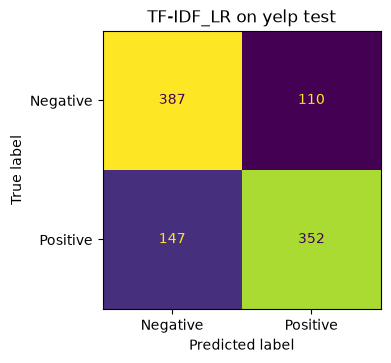


TF-IDF_LR on yelp test
[[387 110]
 [147 352]]


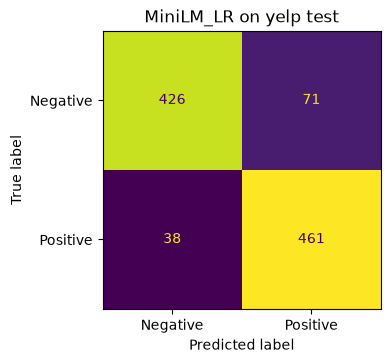


MiniLM_LR on yelp test
[[426  71]
 [ 38 461]]


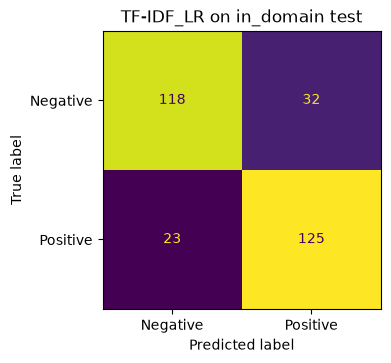


TF-IDF_LR on in_domain test
[[118  32]
 [ 23 125]]


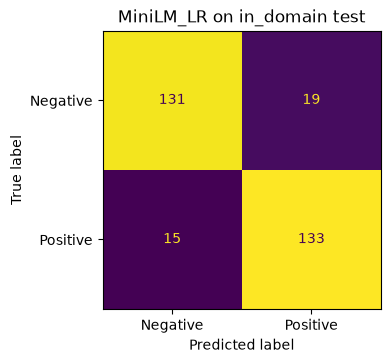


MiniLM_LR on in_domain test
[[131  19]
 [ 15 133]]


In [37]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

CONFUSION_LABELS = ["Negative", "Positive"]


def plot_confusion_matrix(y_true, y_pred, title, save_path):
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=CONFUSION_LABELS)
    fig, ax = plt.subplots(figsize=(4, 4))
    display.plot(ax=ax, colorbar=False)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(save_path)
    plt.show()
    plt.close(fig)
    return matrix


confusion_matrices = {}

for test_set_name in ["yelp", "in_domain"]:
    subset = test_predictions[test_predictions["test_set"] == test_set_name]
    for method_name, pred_col in [("TF-IDF_LR", "pred_tfidf"), ("MiniLM_LR", "pred_minilm")]:
        title = f"{method_name} on {test_set_name} test"
        save_path = RESULTS / f"confusion_matrix_{method_name}_{test_set_name}.png"
        matrix = plot_confusion_matrix(subset["label"], subset[pred_col], title, save_path)
        confusion_matrices[(method_name, test_set_name)] = matrix
        print(f"\n{title}")
        print(matrix)

**Which method performs better on restaurant reviews when trained on product and movie reviews?**

On the Yelp test, the main judgment for this question, MiniLM_LR outperforms TF-IDF_LR: macro F1 0.890 vs 0.742, and accuracy 0.891 vs 0.742. Accuracy and macro F1 agree on this ranking, so there is no disagreement to report between the two metrics.

The in-domain test is a supporting comparison. MiniLM_LR is essentially stable moving from in-domain to Yelp (macro F1 0.886 to 0.890, Δ = +0.5 pp), while TF-IDF_LR drops noticeably (macro F1 0.815 to 0.742, Δ = -7.4 pp). This is a descriptive pattern only: it shows TF-IDF_LR's score fell more than MiniLM_LR's when the text domain changed, not why it fell, and not that MiniLM's representations "understand" sentiment or language in general. Under this one transfer setup, with this training/development data and these settings, the frozen MiniLM sentence-embedding features produced classifier inputs that carried over to restaurant review text better than the TF-IDF vocabulary learned from Amazon and IMDb reviews did. It does not establish that this holds for other domain shifts, and the test set sizes here (298 in-domain, 996 Yelp) mean the exact percentage-point figures carry some sampling noise.

Errors are chosen by a fixed rule, not hand-picked, and are analysed only after the test results above were frozen. This section reads only `results/test_predictions.csv`; it changes no model.

In [38]:
test_predictions_loaded = pd.read_csv(RESULTS / "test_predictions.csv")
yelp_predictions = test_predictions_loaded[test_predictions_loaded["test_set"] == "yelp"].copy()

yelp_predictions["tfidf_correct"] = yelp_predictions["pred_tfidf"] == yelp_predictions["label"]
yelp_predictions["minilm_correct"] = yelp_predictions["pred_minilm"] == yelp_predictions["label"]


def categorize(row):
    if not row["tfidf_correct"] and not row["minilm_correct"]:
        return "both_wrong"
    if not row["tfidf_correct"] and row["minilm_correct"]:
        return "only_tfidf_wrong"
    if row["tfidf_correct"] and not row["minilm_correct"]:
        return "only_minilm_wrong"
    return "both_correct"


yelp_predictions["category"] = yelp_predictions.apply(categorize, axis=1)

category_counts = yelp_predictions["category"].value_counts().reindex(
    ["both_wrong", "only_tfidf_wrong", "only_minilm_wrong", "both_correct"], fill_value=0
)
print(category_counts)

category
both_wrong            48
only_tfidf_wrong     209
only_minilm_wrong     61
both_correct         678
Name: count, dtype: int64


Select up to six examples by a fixed rule: from each of the three error categories, the first two rows ordered by `example_id`.

In [39]:
ERROR_CATEGORIES = ["both_wrong", "only_tfidf_wrong", "only_minilm_wrong"]

selected_examples = []
for category in ERROR_CATEGORIES:
    subset = yelp_predictions[yelp_predictions["category"] == category].sort_values("example_id")
    selected_examples.append(subset.head(2))

selected_examples_df = pd.concat(selected_examples, ignore_index=True)
display_columns = ["category", "example_id", "text", "label", "pred_tfidf", "pred_minilm"]
print(selected_examples_df[display_columns].to_string(index=False))

         category example_id                                                                                                                text  label  pred_tfidf  pred_minilm
       both_wrong  yelp_0034 seems like a good quick place to grab a bite of some familiar pub food, but do yourself a favor and look elsewhere.      0           1            1
       both_wrong  yelp_0049                                                                If you want a sandwich just go to any Firehouse!!!!!      1           0            0
 only_tfidf_wrong  yelp_0006                                                                      Now I am getting angry and I want my damn pho.      0           1            0
 only_tfidf_wrong  yelp_0013                 The cashier had no care what so ever on what I had to say it still ended up being wayyy overpriced.      0           1            0
only_minilm_wrong  yelp_0021                                                                                       

For each selected example, list the words not in the TF-IDF training vocabulary, using `tfidf_model`'s own vectorizer so the same lowercasing and tokenization used to fit it are applied here.

In [40]:
tfidf_vectorizer = tfidf_model.named_steps["tfidf"]
tfidf_vocabulary = set(tfidf_vectorizer.get_feature_names_out())
tfidf_analyzer = tfidf_vectorizer.build_analyzer()


def find_oov_words(text):
    tokens = tfidf_analyzer(text)
    return sorted(set(token for token in tokens if token not in tfidf_vocabulary))


selected_examples_df["oov_words"] = selected_examples_df["text"].apply(find_oov_words)

for _, row in selected_examples_df.iterrows():
    print(f"\n{row['example_id']} ({row['category']}): {row['text']}")
    print(
        f"true={row['label']}, pred_tfidf={row['pred_tfidf']}, pred_minilm={row['pred_minilm']}"
    )
    print("OOV words:", row["oov_words"])


yelp_0034 (both_wrong): seems like a good quick place to grab a bite of some familiar pub food, but do yourself a favor and look elsewhere.
true=0, pred_tfidf=1, pred_minilm=1
OOV words: ['bite', 'familiar', 'favor', 'food', 'grab', 'pub']

yelp_0049 (both_wrong): If you want a sandwich just go to any Firehouse!!!!!
true=1, pred_tfidf=0, pred_minilm=0
OOV words: ['firehouse', 'sandwich']

yelp_0006 (only_tfidf_wrong): Now I am getting angry and I want my damn pho.
true=0, pred_tfidf=1, pred_minilm=0
OOV words: ['pho']

yelp_0013 (only_tfidf_wrong): The cashier had no care what so ever on what I had to say it still ended up being wayyy overpriced.
true=0, pred_tfidf=1, pred_minilm=0
OOV words: ['cashier', 'overpriced', 'wayyy']

yelp_0021 (only_minilm_wrong): The Burrittos Blah!
true=0, pred_tfidf=0, pred_minilm=1
OOV words: ['burrittos']

yelp_0052 (only_minilm_wrong): He came running after us when he realized my husband had left his sunglasses on the table.
true=1, pred_tfidf=1, pred

Over the whole Yelp test set, the share of word tokens not in the training vocabulary. This is a token-level share (every occurrence counts), not a type-level share (distinct words).

In [41]:
def oov_token_share(texts):
    total_tokens = 0
    oov_tokens = 0
    for text in texts:
        tokens = tfidf_analyzer(text)
        total_tokens += len(tokens)
        oov_tokens += sum(token not in tfidf_vocabulary for token in tokens)
    share = oov_tokens / total_tokens if total_tokens else float("nan")
    return oov_tokens, total_tokens, share


yelp_oov_count, yelp_token_count, yelp_oov_share = oov_token_share(yelp_predictions["text"].tolist())
print(
    f"Yelp test OOV token share (token-level): {yelp_oov_count}/{yelp_token_count} "
    f"= {yelp_oov_share:.3f}"
)

Yelp test OOV token share (token-level): 2231/10298 = 0.217


Compare the OOV token share for Yelp sentences TF-IDF_LR got wrong versus right. This is a descriptive comparison only; it does not establish that OOV tokens caused the errors.

In [42]:
tfidf_wrong_texts = yelp_predictions.loc[~yelp_predictions["tfidf_correct"], "text"].tolist()
tfidf_right_texts = yelp_predictions.loc[yelp_predictions["tfidf_correct"], "text"].tolist()

wrong_oov_count, wrong_token_count, wrong_oov_share = oov_token_share(tfidf_wrong_texts)
right_oov_count, right_token_count, right_oov_share = oov_token_share(tfidf_right_texts)

print(
    f"TF-IDF_LR wrong on Yelp: OOV token share = {wrong_oov_count}/{wrong_token_count} "
    f"= {wrong_oov_share:.3f}"
)
print(
    f"TF-IDF_LR right on Yelp: OOV token share = {right_oov_count}/{right_token_count} "
    f"= {right_oov_share:.3f}"
)
print("Descriptive comparison only; it does not establish that OOV tokens caused the errors.")

TF-IDF_LR wrong on Yelp: OOV token share = 622/2794 = 0.223
TF-IDF_LR right on Yelp: OOV token share = 1609/7504 = 0.214
Descriptive comparison only; it does not establish that OOV tokens caused the errors.


Save the selected examples. `possible_explanation` and `cannot_conclude` are left empty for the team to fill in by hand.

In [43]:
error_analysis = selected_examples_df[
    ["example_id", "category", "text", "label", "pred_tfidf", "pred_minilm", "oov_words"]
].copy()
error_analysis["oov_words"] = error_analysis["oov_words"].apply("; ".join)

MANUAL_EXPLANATIONS = {
    "yelp_0013": {
        "possible_explanation": (
            'The main negative cue is "overpriced", which never appears in the '
            "TF-IDF training vocabulary, so TF-IDF could not use it. MiniLM is not "
            "limited to the training vocabulary and predicted Negative correctly."
        ),
        "cannot_conclude": (
            "Across all Yelp errors, OOV share is almost the same for TF-IDF's wrong "
            "and right predictions (22.3% vs 21.4%), so this example does not show OOV "
            "words explain TF-IDF errors in general."
        ),
    },
    "yelp_0006": {
        "possible_explanation": (
            'The negative words "angry" and "damn" are in the TF-IDF vocabulary, '
            "yet TF-IDF still predicted Positive, so this error is not explained by "
            "unknown words. MiniLM, which represents the whole sentence, predicted "
            "Negative correctly."
        ),
        "cannot_conclude": (
            "We cannot tell from the predictions alone which word weights pushed "
            "TF-IDF towards Positive, or why MiniLM got it right."
        ),
    },
    "yelp_0049": {
        "possible_explanation": (
            "The sentence has no clear positive or negative words; its meaning "
            "depends on context (it could praise Firehouse or tell readers to avoid "
            "this restaurant). Both methods predicted Negative."
        ),
        "cannot_conclude": (
            "Without the full original review we cannot be sure the label reflects "
            "the sentence alone; this shows a limit of two-label, sentence-level data "
            "rather than a clear model weakness."
        ),
    },
}

error_analysis["possible_explanation"] = error_analysis["example_id"].map(
    lambda example_id: MANUAL_EXPLANATIONS.get(example_id, {}).get("possible_explanation", "")
)
error_analysis["cannot_conclude"] = error_analysis["example_id"].map(
    lambda example_id: MANUAL_EXPLANATIONS.get(example_id, {}).get("cannot_conclude", "")
)

error_analysis.to_csv(RESULTS / "error_analysis.csv", index=False)
error_analysis

,example_id,category,text,label,pred_tfidf,pred_minilm,oov_words,possible_explanation,cannot_conclude
0,yelp_0034,both_wrong,seems like a good quick place to grab a bite o...,0,1,1,bite; familiar; favor; food; grab; pub,,
1,yelp_0049,both_wrong,If you want a sandwich just go to any Firehous...,1,0,0,firehouse; sandwich,The sentence has no clear positive or negative...,Without the full original review we cannot be ...
2,yelp_0006,only_tfidf_wrong,Now I am getting angry and I want my damn pho.,0,1,0,pho,"The negative words ""angry"" and ""damn"" are in t...",We cannot tell from the predictions alone whic...
3,yelp_0013,only_tfidf_wrong,The cashier had no care what so ever on what I...,0,1,0,cashier; overpriced; wayyy,"The main negative cue is ""overpriced"", which n...","Across all Yelp errors, OOV share is almost th..."
4,yelp_0021,only_minilm_wrong,The Burrittos Blah!,0,0,1,burrittos,,
5,yelp_0052,only_minilm_wrong,He came running after us when he realized my h...,1,1,0,husband; table,,


**Possible explanations for three selected errors** (filled in by the team; the other three rows in `results/error_analysis.csv` are left empty for now).

**yelp_0013** (TF-IDF wrong, MiniLM right) — *possible_explanation:* The main negative cue is "overpriced", which never appears in the TF-IDF training vocabulary, so TF-IDF could not use it. MiniLM is not limited to the training vocabulary and predicted Negative correctly. — *cannot_conclude:* Across all Yelp errors, OOV share is almost the same for TF-IDF's wrong and right predictions (22.3% vs 21.4%), so this example does not show OOV words explain TF-IDF errors in general.

**yelp_0006** (TF-IDF wrong, MiniLM right) — *possible_explanation:* The negative words "angry" and "damn" are in the TF-IDF vocabulary, yet TF-IDF still predicted Positive, so this error is not explained by unknown words. MiniLM, which represents the whole sentence, predicted Negative correctly. — *cannot_conclude:* We cannot tell from the predictions alone which word weights pushed TF-IDF towards Positive, or why MiniLM got it right.

**yelp_0049** (both wrong) — *possible_explanation:* The sentence has no clear positive or negative words; its meaning depends on context (it could praise Firehouse or tell readers to avoid this restaurant). Both methods predicted Negative. — *cannot_conclude:* Without the full original review we cannot be sure the label reflects the sentence alone; this shows a limit of two-label, sentence-level data rather than a clear model weakness.

**Limitations.** This experiment is a single transfer to Yelp; it does not establish generalization to all domains or that either model understands meaning. The new domain is new to the task classifier's training, but we cannot claim it was absent from the MiniLM encoder's own pretraining. Test set sizes differ (298 in-domain vs. 996 Yelp), and the in-domain test is small, so small differences should be read cautiously. Domain and source change together in this data (restaurant reviews are also the only Yelp source), so their effects cannot be fully separated. Mixed, neutral, and sarcastic reviews may not be well represented by the Positive/Negative labels or by this data. The underlying data is limited in size and relatively old, and does not represent all current styles of writing.

## Try it

This cell accepts a new English review and shows the prediction of both methods using the models already trained above. Nothing is retrained here. The tool is meant for short reviews.

`predict_review` cleans the input the same way the training text was cleaned, then predicts with the already-fitted `tfidf_model` and `minilm_model`. It never calls `fit`.

In [44]:
def predict_review(text):
    if text is None or not text.strip():
        print("Please enter a short English review.")
        return None

    cleaned_text = clean_text(text)

    tfidf_prediction = tfidf_model.predict([cleaned_text])[0]
    tfidf_probability = tfidf_model.predict_proba([cleaned_text])[0][tfidf_prediction]

    embedding = encode_texts(minilm_encoder, [cleaned_text])
    minilm_prediction = minilm_model.predict(embedding)[0]
    minilm_probability = minilm_model.predict_proba(embedding)[0][minilm_prediction]

    label_names = {0: "Negative", 1: "Positive"}

    print(f"Review: {text}")
    print(f"TF-IDF_LR : {label_names[tfidf_prediction]} ({tfidf_probability:.2f})")
    print(f"MiniLM_LR : {label_names[minilm_prediction]} ({minilm_probability:.2f})")

    return {
        "tfidf_label": label_names[tfidf_prediction],
        "tfidf_probability": float(tfidf_probability),
        "minilm_label": label_names[minilm_prediction],
        "minilm_probability": float(minilm_probability),
    }

Functional checks on a few hand-picked inputs. These are run checks confirming the cell behaves correctly (clear positive, clear negative, negation, whitespace-only, empty); they are not test results and are not used for any metric.

In [45]:
print("Clear positive example:")
predict_review("The food was absolutely wonderful and the service was great.")

print("\nClear negative example:")
predict_review("The food was terrible and we waited forever.")

print("\nNegation example:")
predict_review("The food was not good.")

print("\nWhitespace-only input:")
predict_review("   ")

print("\nEmpty input:")
predict_review("")

Clear positive example:
Review: The food was absolutely wonderful and the service was great.
TF-IDF_LR : Positive (0.96)
MiniLM_LR : Positive (0.85)

Clear negative example:
Review: The food was terrible and we waited forever.
TF-IDF_LR : Negative (0.95)
MiniLM_LR : Negative (0.73)

Negation example:
Review: The food was not good.
TF-IDF_LR : Negative (0.92)
MiniLM_LR : Negative (0.82)

Whitespace-only input:
Please enter a short English review.

Empty input:
Please enter a short English review.


Interactive cell: change `my_review` below and re-run this cell to try a new review.

In [46]:
my_review = "Type your review here"
predict_review(my_review)

Review: Type your review here


TF-IDF_LR : Negative (0.65)
MiniLM_LR : Positive (0.52)


{'tfidf_label': 'Negative',
 'tfidf_probability': 0.6460748494441519,
 'minilm_label': 'Positive',
 'minilm_probability': 0.5241045355796814}

Save the trained, frozen models so they can be reloaded without retraining.

In [47]:
import joblib

TFIDF_MODEL_PATH = MODELS / "tfidf_model.joblib"
MINILM_CLASSIFIER_PATH = MODELS / "minilm_classifier.joblib"

joblib.dump(tfidf_model, TFIDF_MODEL_PATH)
joblib.dump(minilm_model, MINILM_CLASSIFIER_PATH)

for path in (TFIDF_MODEL_PATH, MINILM_CLASSIFIER_PATH):
    size_mb = path.stat().st_size / (1024 * 1024)
    print(f"{path.name}: {size_mb:.2f} MB")

tfidf_model.joblib: 0.09 MB


minilm_classifier.joblib: 0.00 MB


The MiniLM encoder itself is not saved here; it is reloaded by its model ID (`sentence-transformers/all-MiniLM-L6-v2`), as in the Method 2 section above. Only the trained classifier on top of its frozen embeddings is saved.

## Original examples

Create `results/original_examples.csv` once, with six empty rows (two per member) for the team to fill in by hand. This cell never overwrites an existing file.

In [48]:
ORIGINAL_EXAMPLES_PATH = RESULTS / "original_examples.csv"

if not ORIGINAL_EXAMPLES_PATH.exists():
    original_examples_template = pd.DataFrame(
        {
            "member": [
                "Ali Jafar Altaweel",
                "Ali Jafar Altaweel",
                "Mohammed Moayed Alqurini",
                "Mohammed Moayed Alqurini",
                "Danyal Salman Alhashem",
                "Danyal Salman Alhashem",
            ],
            "date": ["", "", "", "", "", ""],
            "text": ["", "", "", "", "", ""],
            "label": ["", "", "", "", "", ""],
            "reason": ["", "", "", "", "", ""],
        }
    )
    original_examples_template.to_csv(ORIGINAL_EXAMPLES_PATH, index=False)
    print(f"Created {ORIGINAL_EXAMPLES_PATH} with 6 empty rows.")
else:
    print(f"{ORIGINAL_EXAMPLES_PATH} already exists; leaving it unchanged.")

Created C:\Users\moham\Desktop\nlp project\results\original_examples.csv with 6 empty rows.


Read the original examples, skip rows without text yet, and predict with both frozen models. These examples were never used for training or tuning, and this table is kept separate from the test metrics above.

In [54]:
original_examples_df = pd.read_csv(ORIGINAL_EXAMPLES_PATH, dtype=str)
original_examples_with_text = original_examples_df[
    original_examples_df["text"].notna()
    & (original_examples_df["text"].str.strip() != "")
].copy()

if original_examples_with_text.empty:
    print("No original examples with text yet; nothing to predict.")
else:
    cleaned_texts = original_examples_with_text["text"].apply(clean_text)
    original_examples_with_text["pred_tfidf"] = tfidf_model.predict(cleaned_texts.tolist())
    original_embeddings = encode_texts(minilm_encoder, cleaned_texts.tolist())
    original_examples_with_text["pred_minilm"] = minilm_model.predict(original_embeddings)
    print(original_examples_with_text)

NameError: name 'ORIGINAL_EXAMPLES_PATH' is not defined